## Generating new labels for unseen data to increase training set size

This notebook takes the ensemble of three models and runs it on unseen data to generate labels, the labels with very high (>0.80) and very low (<0.20) are kept as positives and negatives for the next round of training while the inbetweens wil be saved  to be checked manually by yours truly. Yeaah. 

In [ ]:
from opensoundscape.annotations import BoxedAnnotations
import numpy as np
import pandas as pd
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt

import opensoundscape as opso
import bioacoustics_model_zoo as bmz
import joblib

import torch, torchaudio
from opensoundscape import Audio

Load the model files, check cuda again always check cuda. 

In [ ]:
sequence=7
sequence_path = f"annotation_step{sequence}"
# create next sequence path
next_seq_path = f"annotation_step{sequence+1}"
Path(next_seq_path).mkdir(exist_ok=True)
resnet = opso.load_model(Path(sequence_path).joinpath("resnet/best.model"))
effnet = opso.load_model(Path(sequence_path).joinpath("effnet/best.model"))
perch = bmz.Perch2ONNX(headless=True)
shallow = joblib.load(Path(sequence_path).joinpath("shallow_perch/shallow_classifier.joblib"))


# load hubert classifier
bundle = torchaudio.pipelines.HUBERT_BASE
hubert = bundle.get_model().eval().to("cuda")
HSR = bundle.sample_rate     # 16 kHz

def hubert_embed_batch(clip_index, batch_size=32, bandpass=False):
    """clip_index: iterable of (file, start, end), e.g. clips_ag.index or train_df.index"""
    keys, out = list(clip_index), []
    for b in range(0, len(keys), batch_size):
        waves = []
        for f, s, e in keys[b:b + batch_size]:
            a = Audio.from_file(f, offset=s, duration=e - s)
            if bandpass:
                a = a.bandpass(20, 1000, order=4)
            x = a.resample(HSR).samples
            n = int(round((e - s) * HSR))
            waves.append(np.pad(x, (0, max(0, n - len(x))))[:n])     # pad/trim to exactly 5 s
        batch = torch.tensor(np.stack(waves), dtype=torch.float32, device="cuda")
        with torch.no_grad():
            feats, _ = hubert.extract_features(batch)
        out.append(feats[-1].mean(dim=1).cpu().numpy())            # last layer, averaged over time
    return np.concatenate(out)

hubert_clf = joblib.load(Path(sequence_path) / "shallow_HUbert"/"shallow_waveform_classifier.joblib")
torch.cuda.is_available()

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(


True

Load the files to check. They will be a combination of the rest of the first airgun folder and some of the "background files"

In [ ]:
from Keys import airgun_folder, background_folder
airgun_folder=Path(airgun_folder)
background_folder=Path(background_folder)
# the files used during training or validation should not be included they can be found here
files_training = pd.read_csv(Path(sequence_path).joinpath("Already_trained_on_files.csv"))

#glob the files for airguns
airgun_files = glob(str(airgun_folder.joinpath('*.wav')))
# erase the first two files that are the joined ones
airgun_files=airgun_files[2:]
# select the one that the model has not been trained on it should be 322
airgun_files = [x for x in  airgun_files if  Path(x).name not in set(files_training.loc[files_training['folder']=="Airgun",'file']) ]


# glob the files for the background
background_files=glob(str(background_folder.joinpath("*.wav")))
background_files=[x for x in  background_files if  Path(x).name not in set(files_training.loc[files_training['folder']=="background",'file']) ]

# subsample 10% of the background noises and 25% of the airguns so i dont use all of them 
import random
import math
random.seed(3101992)
ag_to_select= min(len(airgun_files), max(50,math.floor(len(airgun_files)*0.50)))
bg_to_select =min(len(background_files), max(50, math.floor(len(background_files)*0.5)))
print(f"{len(airgun_files)} airgun and {len(background_files)} background files left")
print(f"selecting {ag_to_select} airgun and {bg_to_select} background files")
if ag_to_select == 0 and bg_to_select == 0:
    raise SystemExit("No unused files left, nothing to label this round.")
airgun_files_s = random.sample(airgun_files, ag_to_select)
background_files_s =random.sample(background_files,bg_to_select )

# add the selected files to the already trained files csv
This_seq_train = pd.DataFrame({
    "file":   [Path(x).name for x in airgun_files_s] + [Path(x).name for x in background_files_s],
    "folder": ["Airgun"] * len(airgun_files_s) + ["background"] * len(background_files_s),
})

files_training_c = pd.concat([files_training, This_seq_train], ignore_index=True)
files_training_c.to_csv(Path(next_seq_path).joinpath(f"Already_trained_on_files.csv"), index=False)

0 airgun and 192 background files left
selecting 0 airgun and 192 background files


extract perch emdeddings  for both files, for the embedding we need to create a clips object so the embedding come out related to a file

In [5]:
clips_ag = opso.utils.make_clip_df(airgun_files_s+background_files_s, clip_duration=5)
perch_emb_ag=np.asanyarray(perch.embed(clips_ag, return_dfs=False, return_preds=False))


  0%|          | 0/384 [00:00<?, ?it/s]

 run the inference in the shallow clasiffier

In [6]:
pred_perch=shallow.predict_proba(perch_emb_ag)[:,1]


Plot the results, we have a nice bimodal distribution but the inbetween section is very large. Hopefully it reduces with each iteration. 

(array([204.,  83.,  40.,  23.,  10.,   9.,   6.,   0.,   4.,   5.]),
 array([0.00696891, 0.10580797, 0.20464703, 0.30348609, 0.40232515,
        0.50116421, 0.60000327, 0.69884233, 0.79768138, 0.89652044,
        0.9953595 ]),
 <BarContainer object of 10 artists>)

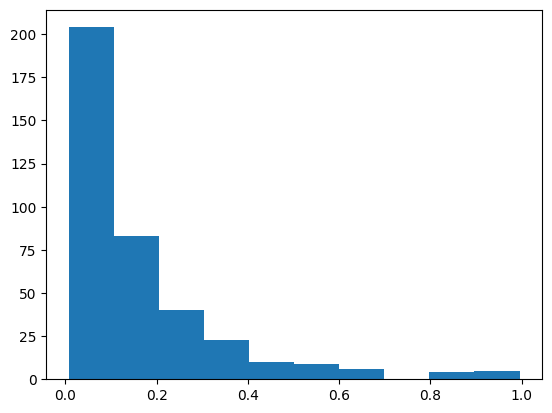

In [7]:
plt.hist(pred_perch)

Creat the prediciton from the hubert model

In [8]:
hubert_emb = hubert_embed_batch(clips_ag.index)
pred_hubert = hubert_clf.predict_proba(hubert_emb)[:, 1]

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/audio.py:2062: UserWarning: Audio object is shorter than requested duration: 4.0 sec instead of 5.0 sec
  warnings.warn(error_msg)
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/audio.py:2062: UserWarning: Audio object is shorter than requested duration: 2.0 sec instead of 5.0 sec
  warnings.warn(error_msg)
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/audio.py:2062: UserWarning: Audio object is shorter than requested duration: 3.0 sec instead of 5.0 sec
  warnings.warn(error_msg)
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/audio.py:2062: UserWarning: Audio object is shorter than requested duration: 4.0 sec instead of 5.0 sec
  warnings.warn(error_msg)


Text(0.5, 1.0, 'Waveform shallow predictor')

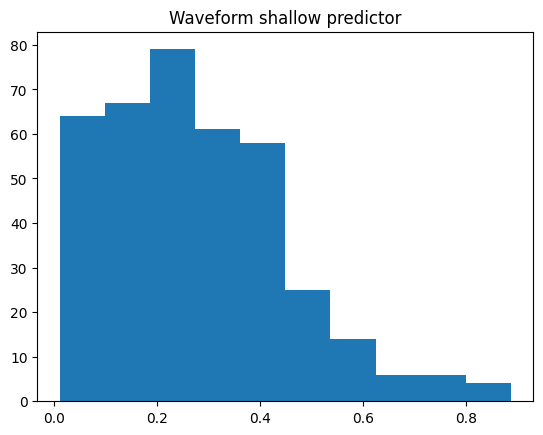

In [9]:
plt.hist(pred_hubert)
plt.title("Waveform shallow predictor")

Create the prediction for the other two models, the argument sigmoid creates true probabilities and the batch needs to be bigger than the default (1) to actually use the gpu. 

In [10]:
pred_resnet = resnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32)
pred_effnet = effnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32)

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

Plot these as well, we have a similar situation as before. 

Text(0.5, 1.0, 'Distribition of scores resnet')

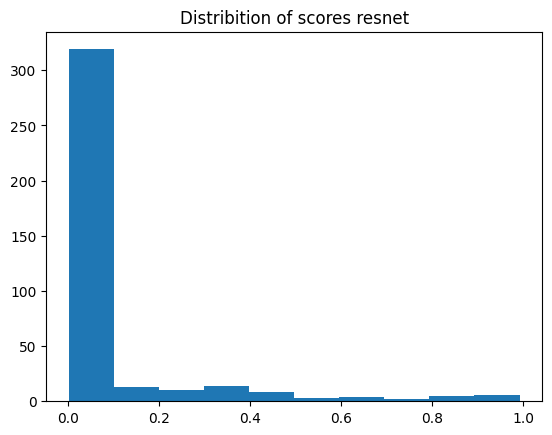

In [11]:
plt.hist(pred_resnet['airgun'])
plt.title("Distribition of scores resnet")

Text(0.5, 1.0, 'Distribition of scores eff_net0')

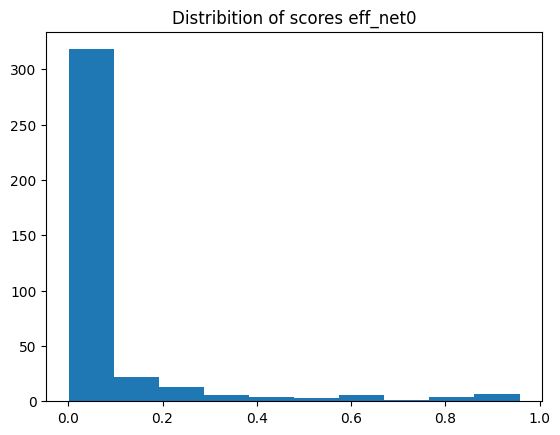

In [12]:
plt.hist(pred_effnet['airgun'])
plt.title("Distribition of scores eff_net0")

Check for the files that are above and below the thresholds for the whole ensamble, here is important to remember that i have twice as many embeddings rows as i have files because most of the files are 10 second and the split was every 5 seconds. 

For the enemble I will use a simple mean of the scores but I will add an additional rule that reject the score if the variation between models was higher than 0.4. 

In [13]:
ens = pd.DataFrame({
    "resnet": pred_resnet["airgun"],
    "effnet": pred_effnet["airgun"],
}, index=clips_ag.index)            
ens["perch"] = pred_perch          
ens["hubert"]=pred_hubert
# hacky way to check for nas that i found.  
assert not ens.isna().any().any()  

ens["mean"] = ens[["resnet", "effnet", "perch"]].mean(axis=1)
ens["spread"] = ens[["resnet", "effnet", "perch"]].max(axis=1) - ens[["resnet", "effnet", "perch"]].min(axis=1)
ens["checked"]=False



Text(0.5, 1.0, 'Distribition of scores for the whole ensemble')

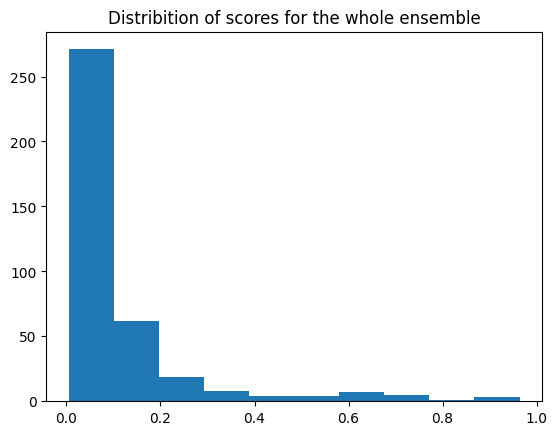

In [14]:
# plot the histogram of the means
plt.hist(ens['mean'])
plt.title("Distribition of scores for the whole ensemble")

In [15]:
upper_th = 0.85
lower_th = 0.07
positives = ens[(ens["mean"] > upper_th) & (ens["spread"] < 0.40)]
negatives = ens[(ens["mean"] < lower_th) & (ens["spread"] < 0.4)]
review    = ens.drop(positives.index).drop(negatives.index)

# indexes of each group in the original dataframe
# positives_index_in_ens = ens[ens.index.isin(positives.index)].index
# negatives_index_in_ens = ens[ens.index.isin(negatives.index)].index
# negatives_index_in_ens = ens[ens.index.isin(review.index)].index


print(len(positives), len(negatives), len(review))

3 221 160


We will check randomly 50%  or 50 of the positives and the negatives to make sure that they are correct. If  estimated max error rate is above  2 percent move the threshold.

- For the positives i will decrease the threshold itertively until the error rate is above 2%, then i will use the previous threshold. 
- For the negatives I wil decrease the theshold iteratively until the error rate is below 2%. 

To avoid having to recheck the same files over and over again I will save the a list of the indexes of the snippets already checked in each iteration. 

In [16]:
from scipy.stats import hypergeom

def max_error_rate(N, n, k, alpha=0.05):
    """N = group size, n = clips checked, k = wrong ones found.
    Returns the upper bound on the group's error rate, in %."""
    D = k
    while D < N and hypergeom.cdf(k, N, D + 1, n) >= alpha:
        D += 1
    return D / N * 100
def optimize_check(N):
    error_rate=100
    k=0
    n=math.floor(0.5*N)
    while error_rate > 2:
        n+=1
        error_rate=max_error_rate(N,n,k)
    return n

In [17]:
from opensoundscape.visualization import annotate
to_check = optimize_check(len(positives))
# reset the index so its not a multindex
positives_df = positives.reset_index()
positives_df["airgun"] = None
old_new_index_dict = {x:y for x,y in zip(positives_df.index, positives.index)}
# pick the clips to check ourselves so we know which ones were actually seen

prev_checked = [i for i in positives_df.index if ens.loc[old_new_index_dict[i], "checked"]]
unchecked = [i for i in positives_df.index if i not in prev_checked]
checked_pos_nc = random.sample(unchecked, min(len(unchecked), max(0, to_check - len(prev_checked))))
checked_pos = prev_checked + checked_pos_nc
# checked_pos = random.sample(list(positives_df.index), to_check)
# ens["checked"] = ens.index.isin([old_new_index_dict.get(x) for x in checked_pos ] )# check the numerical index inside checked pos, but return the that works for ens
#only check the checked pos that have not been checked yet in the previous round we know that all the previous ones are then positive. 
ens.loc[[old_new_index_dict.get(x) for x in checked_pos ],"checked"] = True



widget= annotate(positives_df, indices=checked_pos_nc,
                 N=len(checked_pos_nc),
                 annotation_buttons=['airgun'],bandpass_range=(0,2000),
                 spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

It looks good for the positives, very clear airguns selected. 

In [18]:
# store this run's verdicts in ens, next to the "checked" flag
ens.loc[[old_new_index_dict[x] for x in checked_pos_nc], "is_airgun"] = \
    positives_df.loc[checked_pos_nc, "airgun"].eq(True).values

# count over everything checked in the current group (this run + earlier runs)
keys = [old_new_index_dict[x] for x in checked_pos]
n_checked = len(keys)
n_wrong = (ens.loc[keys, "is_airgun"] != True).sum()
print(f"of {n_checked} checked positives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were wrongly labelled as negatives")
print(f"estimate max error rate {max_error_rate(len(positives), n_checked, n_wrong):.1f}%")

of 3 checked positives, 0 (0.0%) were wrongly labelled as negatives
estimate max error rate 0.0%


again check a % of the negatives tha will allow for 2%max error rate in the labels

In [19]:
negatives_df = negatives.reset_index()
negatives_df["airgun"]=None
to_check_n = optimize_check(len(negatives))
print(f'{to_check_n} are needed to achieve 2%  max error rate')
neg_index_dict = {x: y for x, y in zip(negatives_df.index, negatives.index)}

prev_checked_n = [i for i in negatives_df.index if ens.loc[neg_index_dict[i], "checked"]]
unchecked_n = [i for i in negatives_df.index if i not in prev_checked_n]
checked_neg_nc = random.sample(unchecked_n, min(len(unchecked_n), max(0, to_check_n - len(prev_checked_n))))
checked_neg = prev_checked_n + checked_neg_nc
ens.loc[[neg_index_dict[x] for x in checked_neg], "checked"] = True

widget = annotate(negatives_df, indices=checked_neg_nc, N=len(checked_neg_nc),
                  annotation_buttons=['airgun'], bandpass_range=(0, 3000),
                  spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

111 are needed to achieve 2%  max error rate


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [20]:
# store this run's verdicts in ens
ens.loc[[neg_index_dict[x] for x in checked_neg_nc], "is_airgun"] = \
    negatives_df.loc[checked_neg_nc, "airgun"].eq(True).values

# count over everything checked in the current negative group
keys_n = [neg_index_dict[x] for x in checked_neg]
seen = ens.loc[keys_n]
n_checked = len(seen)
n_wrong = (seen["is_airgun"] == True).sum()
print(f"of {n_checked} checked negatives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were wrongly labelled as negative")
print(f"estimate max error rate {max_error_rate(len(negatives), n_checked, n_wrong):.1f}%")

if n_wrong > 0:
    wrong = seen[seen["is_airgun"] == True]
    print("Score of the negatives that actually contained airguns")
    print(wrong[["resnet", "effnet", "perch", "mean", "spread"]])
    print(f'the suggested new lower bound is {round(wrong["mean"].min(), 2)}')

of 111 checked negatives, 0 (0.0%) were wrongly labelled as negative
estimate max error rate 1.8%


# Test time augmentation to improtve review clips scoring. 

The files that need to be reviwed can be annotated here direclty. However first I am gonna run the neural networks 10 times with random augmentations to see if at least some are made more certain. 

In [21]:
review_clips = review[[]]
def tta(model, n=10):
    runs = [model.predict(review_clips, activation_layer="sigmoid", batch_size=32,
                          bypass_augmentations=False)["airgun"] for _ in range(n)]
    return pd.concat(runs, axis=1).mean(axis=1)

review = review.copy()
tta_resnet = tta(resnet)
tta_effnet = tta(effnet)



  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

... (10 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

you will have to review 160 snippets, get ready!


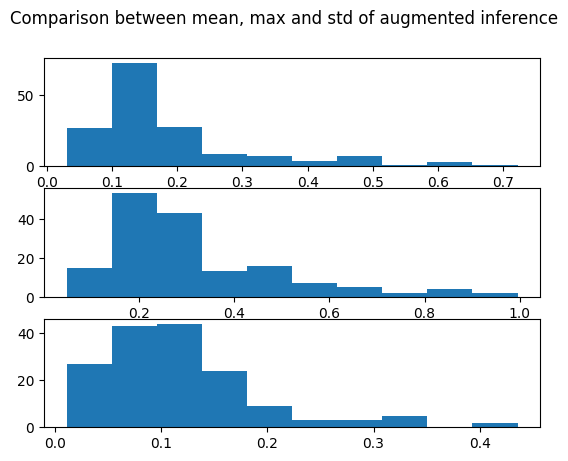

In [22]:
review["tta_mean"] = (tta_resnet + tta_effnet + review["perch"]) / 3
review["tta_max"] = pd.concat([tta_resnet, tta_effnet, review["perch"]], axis=1).max(axis=1)
review["tta_sd"] = pd.concat([tta_resnet, tta_effnet, review["perch"]], axis=1).std(axis=1)
review_df = review.sort_values("tta_mean", ascending=False).reset_index()
review_df_mx = review.sort_values("tta_max", ascending=False).reset_index()

## multiplot comparison of the spread of the scores
fig, axs= plt.subplots(nrows=3, ncols=1)
fig.suptitle("Comparison between mean, max and std of augmented inference")
axs[0].hist(review["tta_mean"])
axs[1].hist(review["tta_max"])
axs[2].hist(review["tta_sd"])

print(f"you will have to review {len(review)} snippets, get ready!")
reviewed = set()         # rows you labelled top-down
checked_rest = set()     # rows of the rest you spot-checked

In [23]:
print(f'Correlation mean-max: {review["tta_mean"].corr(review["tta_max"], method="spearman")}')
print(f'Correlation mean-std: {review["tta_mean"].corr(review["tta_sd"], method="spearman")}')
print(f'Correlation max-std: {review["tta_max"].corr(review["tta_sd"], method="spearman")}')


Correlation mean-max: 0.8760656246820766
Correlation mean-std: 0.5390337513184108
Correlation max-std: 0.827408903235385


The analysis show that there no real difference between using the max or the mean of the tta scores for the review files so im just gonna keep the mean. 

# Bagging Pu Classidier on the review ones
We will use a process called Baggin positives unlabelled classifier. The technique consists on training a classifiers multiple times on  a set of known positives ,known negatives and randomly selected reviews. The resulting model is then ran on the non selected reviews and the scores are saved. The result is the model can tell me which of the unlabelled ones are more likely to be an airgun. This works better than running the network 10 times since, unless the network has a strong dropout then 

In [24]:
from sklearn.linear_model import LogisticRegression
from pulearn import BaggingPuClassifier
shallow = LogisticRegression(max_iter=5000, class_weight="balanced")
pu_estimator = BaggingPuClassifier(estimator = shallow,n_estimators= 100, 
                                   max_samples = 0.4, oob_score=True)
# use the embedding of the positives the negatives and the reveiws based on the threshold we used. 
emb_positive  = perch.embed(positives)
emb_negative= perch.embed(negatives)
emb_review = perch.embed(review)


/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/ml/cnn.py:2930: UserWarning: The columns of input samples df differ from `model.classes`. Discarding sample df columns.
  warnings.warn(


  0%|          | 0/3 [00:00<?, ?it/s]

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/ml/cnn.py:2930: UserWarning: The columns of input samples df differ from `model.classes`. Discarding sample df columns.
  warnings.warn(


  0%|          | 0/221 [00:00<?, ?it/s]

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/ml/cnn.py:2930: UserWarning: The columns of input samples df differ from `model.classes`. Discarding sample df columns.
  warnings.warn(


  0%|          | 0/160 [00:00<?, ?it/s]

In [25]:
X=np.concatenate([emb_positive, emb_negative, emb_review])
y = np.repeat([1,0,0],[len(positives), len(negatives), len(review)])

pu_estimator.fit(X,y)

,estimator,LogisticRegre...max_iter=5000)
,n_estimators,100
,max_samples,0.4
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,True
,warm_start,False
,n_jobs,1
,random_state,None
,verbose,0


Correlation mean-bagscore: 0.03314191960623462


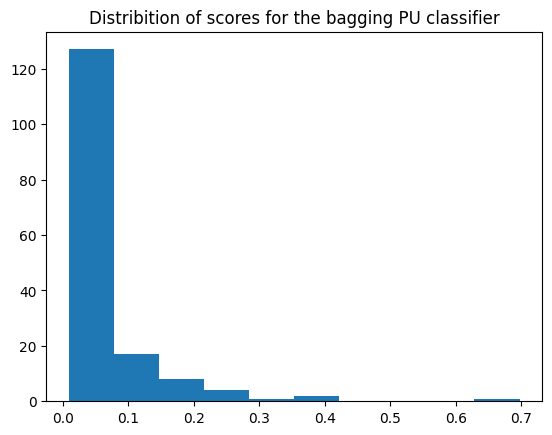

In [26]:
review_df["bag_score"] = pu_estimator.oob_decision_function_[-len(review):, 1]
plt.hist(review_df["bag_score"])
plt.title("Distribition of scores for the bagging PU classifier")
print(f'Correlation mean-bagscore: {review_df["tta_mean"].corr(review_df["bag_score"], method="spearman")}')

In [29]:
review_df.sort_values(by=['tta_mean'], ascending=False)

,file,start_time,end_time,resnet,effnet,perch,hubert,mean,spread,checked,tta_mean,tta_max,tta_sd,bag_score
0,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.640888,0.241039,0.938474,0.398657,0.606800,0.697435,False,0.721487,0.938474,0.242679,0.010995
1,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.897436,0.816730,0.626927,0.707733,0.780364,0.270510,False,0.610186,0.653714,0.053885,0.039112
2,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.966830,0.870867,0.398910,0.339568,0.745535,0.567920,False,0.601060,0.743155,0.179808,0.019462
3,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.833679,0.521933,0.887355,0.355664,0.747656,0.365421,False,0.600952,0.887355,0.289286,0.029893
4,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,0.0,5.0,0.687730,0.776596,0.590662,0.270073,0.684996,0.185934,False,0.543981,0.590662,0.040985,0.020270
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.042726,0.037252,0.134427,0.354936,0.071468,0.097174,False,0.077564,0.134427,0.050841,0.052977
156,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,5.0,10.0,0.135420,0.073941,0.096448,0.202685,0.101936,0.061478,False,0.075319,0.101087,0.040679,0.042180
157,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,0.0,5.0,0.001043,0.034078,0.178876,0.119426,0.071332,0.177834,False,0.074805,0.178876,0.092013,0.014928
158,/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Ca...,0.0,5.0,0.229429,0.023494,0.020621,0.192074,0.091181,0.208808,False,0.068335,0.108780,0.044527,0.016091


# Reviewing of the unlabeleed clips

In [30]:
unseen = [i for i in review_df.index if i not in reviewed and i not in checked_rest]
idx = unseen[:50]
reviewed.update(idx)
annotate(review_df, indices=idx, annotation_buttons=["airgun"], N=len(idx),
         bandpass_range=(0, 1500), spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})
review_df.to_csv(Path(next_seq_path).joinpath("review_progress.csv"), index=False)

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [31]:
seen = reviewed | checked_rest
bag_top = [i for i in review_df.sort_values("bag_score", ascending=False).index if i not in seen][:30]
reviewed.update(bag_top)
widget = annotate(review_df, indices=bag_top, N=len(bag_top), annotation_buttons=["airgun"],
                  bandpass_range=(0, 1500), spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [32]:
rest_idx = [i for i in review_df.index if i not in reviewed]
N = len(rest_idx)

if N == 0:
    sample_rest = []
    print("no rest left, every clip was reviewed by hand")
else:
    n_needed = optimize_check(N)
    k_allowed = max([k for k in range(n_needed + 1) if max_error_rate(N, n_needed, k) <= 2], default=None)
    print(f"{N} clips treated as negatives, check {n_needed}; max airguns allowed in the sample: {k_allowed}")

    prev = [i for i in rest_idx if i in checked_rest]
    new = random.sample([i for i in rest_idx if i not in checked_rest], max(0, n_needed - len(prev)))
    sample_rest = prev + new
    checked_rest.update(new)

    widget = annotate(review_df, indices=new, N=len(new), annotation_buttons=["airgun"],
                      bandpass_range=(0, 1500), spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

80 clips treated as negatives, check 62; max airguns allowed in the sample: 0


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [33]:
if N == 0:
    print("nothing to accept, all clips were labelled by hand")
else:
    k = review_df.loc[sample_rest, "airgun"].eq(True).sum()
    rate = max_error_rate(N, len(sample_rest), k)
    print(f"{k} airguns in {len(sample_rest)} checked, max error rate {rate:.1f}%")
    if rate <= 2:
        print("accepted: the rest are negatives")
    else:
        print("not accepted: review another batch, then run the sample cell again")

0 airguns in 62 checked, max error rate 1.2%
accepted: the rest are negatives


Print all the added airguns to the dataset

In [34]:
pos_idx = list(review_df.index[review_df["airgun"] == 1])
print(len(pos_idx))          # should be 31

widget = annotate(review_df, indices=pos_idx, N=len(pos_idx),
         bandpass_range=(0, 1500),
         spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

13


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [35]:
print(f"from  a total of {len(review)} review files {(review_df['airgun'].eq(True)).sum()} are airguns and the rest are nothing (negatives)")

from  a total of 160 review files 13 are airguns and the rest are nothing (negatives)


In [36]:
# copy the labels from the resnet to have the template
labels = pred_resnet.copy()               
# set an airgun column to 0 
labels["airgun"] = 0                        

# reviewed airguns by file + times, not by row number
rev_keys = review_df.loc[review_df["airgun"].eq(True), ["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(rev_keys), "airgun"] = 1

pos_keys = positives_df[["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(pos_keys), "airgun"] = 1

print(labels["airgun"].value_counts())   



airgun
0    368
1     16
Name: count, dtype: int64


Save as a set of raven tables and as csv usable for future training. I dont have a lot of use for the annotations in raven Right now because of Raven lite but maybe they can be useful. 

TODO: finish this part, it needs to save the raven files in the correct folder and then merged the labels of the previous and current, also it needs to load the labels from the previous sequence if it is not the first one. 

 Load the annotations of the previous iteration in the sequence, if it is ther first iteration then load the training set if not then load the ones from the previous folder. 

In [37]:
from Keys import annotation_file_tr_og, audio_file_file_tr_og
CORE = ["audio_file", "annotation", "start_time", "end_time", "low_f", "high_f"]

# 1. previous training set
if sequence == 0:
    prev = BoxedAnnotations.from_raven_files(raven_files=[annotation_file_tr_og],
                                             audio_files=[audio_file_file_tr_og],
                                             annotation_column=None)
    prev_files = [str(audio_file_file_tr_og)]
else:
    prev = BoxedAnnotations.from_csv(Path(sequence_path) / f"training_set_step{sequence}.csv")
    prev_files = pd.read_csv(Path(sequence_path) / f"training_set_step{sequence}_audio_files.csv")["audio_file"].tolist()
prev.df["annotation"] = "airgun"

# 2. this step's annotations
current_ann = labels[labels["airgun"] == 1].reset_index()
df = pd.DataFrame({"audio_file": current_ann["file"], "start_time": current_ann["start_time"],
                   "end_time": current_ann["end_time"], "annotation": "airgun",
                   "low_f": 0, "high_f": 3000})
all_files_current = labels.index.get_level_values("file").unique().tolist()

# 3. merge
combined_files = list(dict.fromkeys(prev_files + all_files_current))
training_set = BoxedAnnotations(pd.concat([prev.df[CORE], df], ignore_index=True),
                                audio_files=combined_files)

# 4. save for the next step
out = Path(next_seq_path)
training_set.to_csv(out / f"training_set_step{sequence + 1}.csv")
pd.DataFrame({"audio_file": combined_files}).to_csv(out / f"training_set_step{sequence + 1}_audio_files.csv", index=False)

raven_dir = out / "raven annotations"; raven_dir.mkdir(exist_ok=True)
BoxedAnnotations(df, audio_files=all_files_current).to_raven_files(raven_dir)

prev_labels = prev.clip_labels(clip_duration=5, clip_overlap=0, min_label_overlap=0.25,
                               audio_files=prev_files)
pp, pn = int(prev_labels["airgun"].sum()), int((prev_labels["airgun"] == 0).sum())
cp, cn = int(labels["airgun"].sum()), int((labels["airgun"] == 0).sum())

print(f"Sequence {sequence} finished, positives: {pp} previous + {cp} new = {pp + cp}")
print(f"negatives: {pn} previous + {cn} new = {pn + cn}")

Sequence 6 finished, positives: 647 previous + 16 new = 663
negatives: 1762 previous + 368 new = 2130
